# Logistic Regression:

## 1. Purpose of Logistic Regression: Best Classification

The goal of `Logistic Regression` is to find the best classifier (decision boundary) that effectively separates two classes by estimating the probability of a sample belonging to class 1.

- Unlike Linear Regression, which predicts continuous values, Logistic Regression transforms inputs into probabilities using the **sigmoid function** and classifies them into two categories (e.g., 0 or 1).
- It works well for binary classification problems, such as spam detection, fraud detection, and disease prediction.

<img src="images/binary.ppm" width='350px'>

### Mathematical Representation
For a given set of input features $X$, the logistic function is:

$$
h(X) = \frac{1}{1 + e^{-(w^T x + b)}}
$$

where:
- $h(X)$ is the probability that the point belongs to **class 1**.
- $w$ is the **weight vector** (parameters to be learned).
- $x$ is the **feature vector**.
- $b$ is the **bias term**.

The best classifier maximizes the separation between the two classes.

---

## 3. Assumptions in Logistic Regression
1. **Binary Output**: The target variable should have only two categories (e.g., spam or not spam).
2. **Linear Log-Odds Relationship**: The independent variables should have a linear relationship with the **log-odds** of the dependent variable.
3. **No Multicollinearity**: Independent variables should not be highly correlated.
4. **Independence of Observations**: Each observation should be independent.
5. **Large Dataset Size**: Logistic Regression performs best with large, well-balanced datasets.

---

In [ ]:
## 

### 2. Equations of Decision Boundary: Line and Plane

#### Equation of a Decision Boundary in 2D (Line)
In a two-dimensional space, the decision boundary is a straight line given by:

$$
w^T x + b = 0
$$

Expanding it in terms of coordinates:

$$
w_1 X_1 + w_2 X_2 + b = 0
$$

where:
- $w_1, w_2$ are the weights (coefficients) for features $X_1, X_2$.
- $b$ is the bias term.

### Equation of a Decision Boundary in Higher Dimensions (Plane/Hyperplane)
For an $n$-dimensional space, the decision boundary is a **hyperplane**:

$$
w^T x + b = w_1 X_1 + w_2 X_2 + ... + w_n X_n + b = 0
$$

- If $w^T x + b > 0$ → Class 1
- If $w^T x + b < 0$ → Class 0

---


In [ ]:
## 

## Working of Logistic Regression: Distance Calculation

To classify a point correctly, we calculate its distance from the decision boundary.

### Distance from a Point to a Line (2D Space)
For a point $(X_1, X_2)$, the perpendicular distance **$d$** from the decision boundary is given by:

$$
d = \frac{|w^T x + b|}{\| w \|}
$$

### Distance from a Point to a Hyperplane (Higher Dimension)
For a point $(X_1, X_2, ..., X_n)$ in an $n$-dimensional space, the distance is:

$$
d = \frac{|w^T x + b|}{\| w \|}
$$

This distance determines whether the point is classified correctly.

---

In [ ]:
## 

### Condition for Finding the Best Classifier Line or Plane

The best classifier is chosen bymaximizing the sum of correct classifications, given by the **argmax equation**:

$$
\underset{w,b}{\arg\max} \sum_{i=1}^{m} y_i (w^T x_i + b)
$$

This means:
- We compute $w^T x_i + b$ for each training sample $x_i$.
- The classifier that maximizes this summation is the best decision boundary.

---


In [ ]:
## 


## Four Cases in Classification

| Case | Condition | Distance Calculation | Correct Classification? |
|------|-----------|----------------------|-------------------------|
| 1. Positive point in positive region | $w^T x + b > 0$ and actual class = 1 | Distance is positive | Correct ✅ |
| 2. Negative point in negative region | $w^T x + b < 0$ and actual class = -1 | Distance is negative | Correct ✅ |
| 3. Negative point in positive region | $w^T x + b > 0$ but actual class = -1 | Distance is positive | Incorrect ❌ |
| 4. Positive point in negative region | $w^T x + b < 0$ but actual class = 1 | Distance is negative | Incorrect ❌ |

Thus, cases 3 and 4 indicate misclassification while cases 1 and 2 indicate correct classification

---

In [ ]:
## 


### Condition after training:
After training the model, the final decision boundary equation is:

$$
w^T x + b = 0
$$

This equation **divides the feature space into two regions**:
- Region 1 (+ class): $w^T x + b > 0$
- Region 0 (- class): $w^T x + b < 0$

The **classifier with the highest** $ \sum y_i (w^T x_i + b) $ is chosen as the best classifier.

---




In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = sns.load_dataset('penguins')

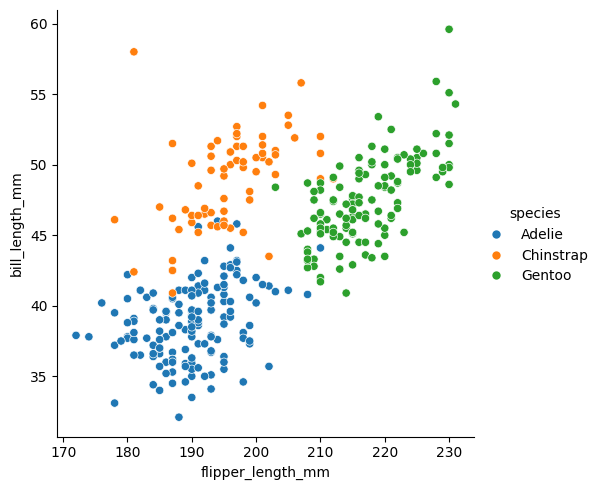

In [37]:
sns.relplot(data=df, x="flipper_length_mm", y="bill_length_mm",hue='species')


ValueError: The following variable cannot be assigned with wide-form data: `hue`

In [34]:
df['species'].unique() # Output column

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

In [ ]:
print(df['island'].unique()) # One hot encoding
print(df['sex'].unique())

In [ ]:
df.isnull().sum()

In [ ]:
df.shape

In [ ]:
df = df.dropna() # Eliminate null values.

- Currently focusing on binary classification:

In [ ]:
df = df[df['species']!='Chinstrap']
print(df['species'].unique())
print(df['species'].nunique())
print(df.shape)

In [ ]:
df.info()

- Now Output Column Species Have two unique values : 'Adelie' and 'Gentoo'

- Dividing the dataset into independent and dependent variable.

In [ ]:
df.head(2)

In [ ]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

- Spliting into traing and testing set.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                    test_size=0.2,random_state=0)

In [ ]:
X_train.sample(3)

### Modify data for model ready....

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler

In [22]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

In [23]:
ct = ColumnTransformer(transformers=[
    ('t1',OneHotEncoder(),['island','sex']),
    ('t2',MinMaxScaler(),['bill_length_mm', 'bill_depth_mm', 
                    'flipper_length_mm', 'body_mass_g'])
],remainder='passthrough')

In [24]:
ct.fit(X_train)

ColumnTransformer(remainder='passthrough',
                  transformers=[('t1', OneHotEncoder(), ['island', 'sex']),
                                ('t2', MinMaxScaler(),
                                 ['bill_length_mm', 'bill_depth_mm',
                                  'flipper_length_mm', 'body_mass_g'])])

In [25]:
new_X_train = ct.transform(X_train)
new_X_test = ct.transform(X_test)

In [26]:
print(new_X_train.shape)
print(new_X_test.shape)

(212, 9)
(53, 9)


In [27]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()

In [28]:
lr.fit(new_X_train,y_train)

/Users/shailesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/shailesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/shailesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/shailesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/shailesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_point

LogisticRegression()

In [29]:
y_pred = lr.predict(new_X_test)

In [30]:
from sklearn.metrics import accuracy_score, classification_report

In [31]:
accuracy_score(y_pred,y_test)

1.0

In [32]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        29
      Gentoo       1.00      1.00      1.00        24

    accuracy                           1.00        53
   macro avg       1.00      1.00      1.00        53
weighted avg       1.00      1.00      1.00        53



In [ ]:
df1 = sns.load_dataset('titanic')

In [ ]:
df1.sample(3)

In [ ]:
df1.info()

- Understanding Data:

In [ ]:
df1.isnull().sum()

In [ ]:
df1 = df1.drop(columns='deck')

In [ ]:
df1 = df1.drop(columns='embark_town')

In [ ]:
df1 = df1.drop(columns='class')

In [ ]:
df1['age'] = df1['age'].fillna(df1['age'].mean())

In [ ]:
df1 = df1.dropna()

In [ ]:
df1.isnull().sum()

In [ ]:
df1.info()

In [ ]:
df1.sample()

In [ ]:
df1['who'].unique()

In [ ]:
df1.columns

sex, embarked, who, adult_male, alive, alone -> nominal     
pclass, -> ordinal     
age, fare -> numerical     

In [ ]:
X = df1.iloc[:,1:]
y = df1.iloc[:,0]

- Spliting into traing and testing set.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,random_state=0)

In [ ]:
X_train.sample(3)

In [ ]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

In [ ]:
ct1 = ColumnTransformer(transformers=[
    ('t1', OneHotEncoder(sparse_output=False, drop='first'),['sex','embarked', 'who', 'adult_male', 'alive', 'alone']),
    ('t2',MinMaxScaler(),['age','fare'])
], remainder='passthrough')

In [ ]:
ct1.fit(X_train)

In [ ]:
X_train_s = ct1.transform(X_train)
X_test_s = ct1.transform(X_test)

In [ ]:
X_train_s.shape

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

In [ ]:
lr.fit(X_train_s,y_train)

In [ ]:
y_pred = lr.predict(X_test_s)

In [ ]:
y_pred

In [ ]:
import numpy as np
np.array(y_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
accuracy_score(y_pred,y_test)

In [ ]:
print(classification_report(y_pred,y_test))